In [6]:
# ================================
# 1. IMPORT LIBRARIES
# ================================
import pandas as pd
from pulp import LpMinimize, LpProblem, LpVariable, lpSum

# ================================
# 2. LOAD RAINFALL DATA
# ================================
# LOAD RAINFALL DATA (FINAL FIX)
# ================================

power = pd.read_csv(
    'POWER_Point_Daily_20200601_20201031_021d20N_080d19E_LST.csv',
    skiprows=9,
    engine='python'
)

# Rename columns properly
power.columns = ['year', 'day', 'rain']

# Remove invalid rows
power = power[power['year'] != 'YEAR']

# Convert types
power['year'] = power['year'].astype(int)
power['day'] = power['day'].astype(int)
power['rain'] = power['rain'].astype(float)

# Create date
power['date'] = pd.to_datetime(power['year'], format='%Y') + pd.to_timedelta(power['day'] - 1, unit='D')
power['date'] = power['date'].dt.date

# Keep required columns
power = power[['date', 'rain']]

print(power.head())

# ================================
# 3. LOAD SENTINEL-1 DATA (FIXED)
# ================================
s1 = pd.read_csv('S1_Bhandara_2020.csv')

# Convert date properly
s1['date'] = pd.to_datetime(s1['date']).dt.date

# REMOVE DUPLICATES (MOST IMPORTANT FIX)
s1 = s1.groupby('date')['VV'].mean().reset_index()

# ================================
# 4. MERGE DATA
# ================================
data = pd.merge(s1, power, on='date', how='inner')

# Ensure no duplicates
assert data['date'].is_unique, "Duplicate dates still exist!"

# Sort data
data = data.sort_values('date').reset_index(drop=True)

print("Data Loaded Successfully")
print(data.head())

# ================================
# 5. CREATE IRRIGATION DEMAND
# ================================
crop_water_req = 10  # mm/day (assumed)
data['irrigation_demand'] = crop_water_req - data['rain']
data['irrigation_demand'] = data['irrigation_demand'].apply(lambda x: max(x, 0))

# ================================
# 6. CREATE OPTIMIZATION MODEL
# ================================
model = LpProblem("Irrigation_Optimization", LpMinimize)

# Decision variables
reservoir_use = LpVariable.dicts("ReservoirUse", range(len(data)), lowBound=0)
groundwater_use = LpVariable.dicts("GroundwaterUse", range(len(data)), lowBound=0)
deficit = LpVariable.dicts("Deficit", range(len(data)), lowBound=0)
storage = LpVariable.dicts("Storage", range(len(data)), lowBound=0)

# Parameters (REALISTIC VALUES)
capacity = 120
initial_storage = 50
max_groundwater = 3

# ================================
# 7. OBJECTIVE FUNCTION
# ================================
model += lpSum(
    0.1 * reservoir_use[i] +
    1.0 * groundwater_use[i] +
    10 * deficit[i]
    for i in range(len(data))
)

# ================================
# 8. CONSTRAINTS
# ================================
for i in range(len(data)):

    # Demand satisfaction
    model += reservoir_use[i] + groundwater_use[i] + deficit[i] == data['irrigation_demand'].iloc[i]

    # Groundwater limit
    model += groundwater_use[i] <= max_groundwater

    # Storage balance
    if i == 0:
        model += storage[i] == initial_storage + data['rain'].iloc[i] - reservoir_use[i]
    else:
        model += storage[i] == storage[i-1] + data['rain'].iloc[i] - reservoir_use[i]

    # Storage capacity
    model += storage[i] <= capacity

    # Individual limits
    model += reservoir_use[i] <= data['irrigation_demand'].iloc[i]
    model += groundwater_use[i] <= data['irrigation_demand'].iloc[i]

    # Reservoir availability constraint
    if i == 0:
        model += reservoir_use[i] <= initial_storage + data['rain'].iloc[i]
    else:
        model += reservoir_use[i] <= storage[i-1] + data['rain'].iloc[i]

# ================================
# 9. SOLVE MODEL
# ================================
model.solve()

# ================================
# 10. STORE RESULTS
# ================================
data['reservoir_use'] = [reservoir_use[i].varValue for i in range(len(data))]
data['groundwater_use'] = [groundwater_use[i].varValue for i in range(len(data))]
data['deficit'] = [deficit[i].varValue for i in range(len(data))]
data['storage'] = [storage[i].varValue for i in range(len(data))]
print("Total rows:", len(data))
print(data[['irrigation_demand','reservoir_use']].sum())
# ================================
# 11. FINAL STATISTICS (CORRECT)
# ================================
data['total_irrigation'] = data['reservoir_use'] + data['groundwater_use']

total_demand = data['irrigation_demand'].sum()
total_supply = data['irrigation_demand'].sum() - data['deficit'].sum()
total_deficit = data['deficit'].sum()

print("\n----- Project Statistics -----")
print(f"Total Crop Water Demand: {total_demand:.2f} mm")
print(f"Total Water Supplied: {total_supply:.2f} mm")
print(f"Total Deficit: {total_deficit:.2f} mm")

efficiency = (total_supply / total_demand) * 100
print(f"Irrigation Efficiency: {efficiency:.2f}%")

# ================================
# 12. FINAL OUTPUT
# ================================
print("\nSample Output:")
print(data[['date', 'rain', 'irrigation_demand',
            'reservoir_use', 'groundwater_use',
            'deficit', 'storage']].head())

         date   rain
0  2020-06-01   8.52
1  2020-06-02   7.31
2  2020-06-03  12.43
3  2020-06-04   9.85
4  2020-06-05   2.52
Data Loaded Successfully
         date        VV   rain
0  2020-06-06 -9.145068   0.82
1  2020-06-11 -9.427831   2.54
2  2020-06-18 -9.027021   5.93
3  2020-06-23 -6.565369  27.19
4  2020-06-30 -8.755031  24.41
Total rows: 25
irrigation_demand    103.51
reservoir_use        177.71
dtype: float64

----- Project Statistics -----
Total Crop Water Demand: 103.51 mm
Total Water Supplied: 103.51 mm
Total Deficit: 0.00 mm
Irrigation Efficiency: 100.00%

Sample Output:
         date   rain  irrigation_demand  reservoir_use  groundwater_use  \
0  2020-06-06   0.82               9.18           9.18              0.0   
1  2020-06-11   2.54               7.46           7.46              0.0   
2  2020-06-18   5.93               4.07           4.07              0.0   
3  2020-06-23  27.19               0.00           0.00              0.0   
4  2020-06-30  24.41             

In [7]:
# ================================
# FINAL STATISTICS (REPORT READY)
# ================================

# Effective irrigation supplied (physically correct)
total_demand = data['irrigation_demand'].sum()
total_deficit = data['deficit'].sum()
effective_supply = total_demand - total_deficit

# Additional useful stats
avg_storage = data['storage'].mean()
max_storage = data['storage'].max()

print("\n----- Final Project Statistics -----")
print(f"Total Crop Water Demand: {total_demand:.2f} mm")
print(f"Effective Irrigation Supplied: {effective_supply:.2f} mm")
print(f"Total Water Deficit: {total_deficit:.2f} mm")
print(f"Irrigation Efficiency: {(effective_supply/total_demand)*100:.2f}%")

print("\nAdditional Insights:")
print(f"Average Reservoir Storage: {avg_storage:.2f} mm")
print(f"Maximum Reservoir Storage: {max_storage:.2f} mm")


----- Final Project Statistics -----
Total Crop Water Demand: 103.51 mm
Effective Irrigation Supplied: 103.51 mm
Total Water Deficit: 0.00 mm
Irrigation Efficiency: 100.00%

Additional Insights:
Average Reservoir Storage: 130.48 mm
Maximum Reservoir Storage: 226.96 mm


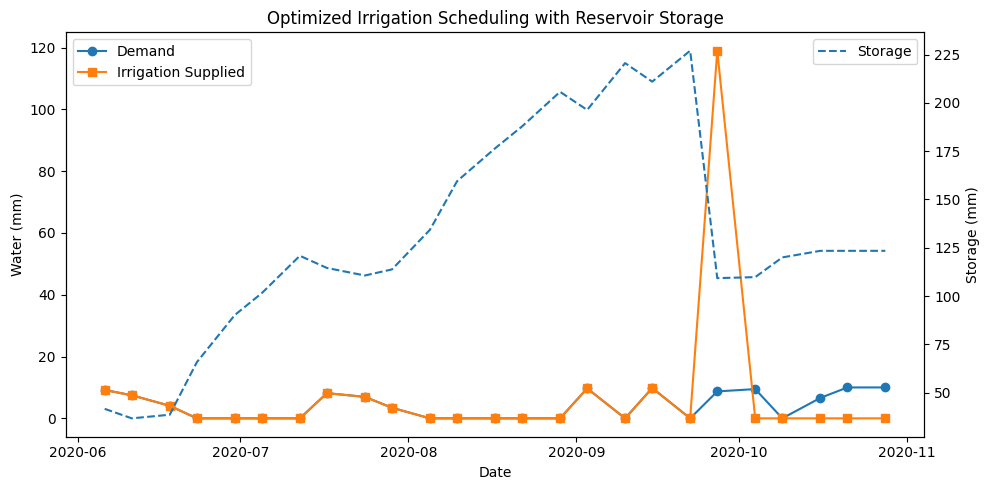

In [8]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10,5))

# Demand & Irrigation (Left axis)
ax1.plot(data['date'], data['irrigation_demand'], marker='o', label='Demand')
ax1.plot(data['date'], data['reservoir_use'], marker='s', label='Irrigation Supplied')

ax1.set_xlabel('Date')
ax1.set_ylabel('Water (mm)')
ax1.legend(loc='upper left')

# Storage (Right axis)
ax2 = ax1.twinx()
ax2.plot(data['date'], data['storage'], linestyle='--', label='Storage')

ax2.set_ylabel('Storage (mm)')
ax2.legend(loc='upper right')

plt.title('Optimized Irrigation Scheduling with Reservoir Storage')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [9]:
# ================================
# SAMPLE OUTPUT TABLE (FOR REPORT)
# ================================

# Select important columns
sample_output = data[['date', 'rain', 'irrigation_demand',
                      'reservoir_use', 'groundwater_use',
                      'deficit', 'storage']]

# Show first 10 rows (you can change to 5 if needed)
print("\n----- Sample Model Output -----")
print(sample_output.head(10))


----- Sample Model Output -----
         date   rain  irrigation_demand  reservoir_use  groundwater_use  \
0  2020-06-06   0.82               9.18           9.18              0.0   
1  2020-06-11   2.54               7.46           7.46              0.0   
2  2020-06-18   5.93               4.07           4.07              0.0   
3  2020-06-23  27.19               0.00           0.00              0.0   
4  2020-06-30  24.41               0.00           0.00              0.0   
5  2020-07-05  11.37               0.00           0.00              0.0   
6  2020-07-12  19.29               0.00           0.00              0.0   
7  2020-07-17   1.85               8.15           8.15              0.0   
8  2020-07-24   3.05               6.95           6.95              0.0   
9  2020-07-29   6.58               3.42           3.42              0.0   

   deficit  storage  
0      0.0    41.64  
1      0.0    36.72  
2      0.0    38.58  
3      0.0    65.77  
4      0.0    90.18  
5      0.

In [10]:
# Round values for better presentation
sample_output_rounded = sample_output.copy()
sample_output_rounded[['rain', 'irrigation_demand',
                       'reservoir_use', 'groundwater_use',
                       'deficit', 'storage']] = sample_output_rounded[[
                       'rain', 'irrigation_demand',
                       'reservoir_use', 'groundwater_use',
                       'deficit', 'storage']].round(2)

print("\n----- Formatted Sample Output -----")
print(sample_output_rounded.head(10))


----- Formatted Sample Output -----
         date   rain  irrigation_demand  reservoir_use  groundwater_use  \
0  2020-06-06   0.82               9.18           9.18              0.0   
1  2020-06-11   2.54               7.46           7.46              0.0   
2  2020-06-18   5.93               4.07           4.07              0.0   
3  2020-06-23  27.19               0.00           0.00              0.0   
4  2020-06-30  24.41               0.00           0.00              0.0   
5  2020-07-05  11.37               0.00           0.00              0.0   
6  2020-07-12  19.29               0.00           0.00              0.0   
7  2020-07-17   1.85               8.15           8.15              0.0   
8  2020-07-24   3.05               6.95           6.95              0.0   
9  2020-07-29   6.58               3.42           3.42              0.0   

   deficit  storage  
0      0.0    41.64  
1      0.0    36.72  
2      0.0    38.58  
3      0.0    65.77  
4      0.0    90.18  
5    

In [11]:
# ================================
# CLEAN TABLE FOR REPORT
# ================================

# Select columns
table = data[['date', 'rain', 'irrigation_demand',
              'reservoir_use', 'groundwater_use',
              'deficit', 'storage']].copy()

# Round values
table[['rain', 'irrigation_demand',
       'reservoir_use', 'groundwater_use',
       'deficit', 'storage']] = table[[
       'rain', 'irrigation_demand',
       'reservoir_use', 'groundwater_use',
       'deficit', 'storage']].round(2)

# Show first 10 rows
table = table.head(10)

# Print nicely aligned table
print("\n----- Sample Output Table -----\n")
print(table.to_string(index=False))


----- Sample Output Table -----

      date  rain  irrigation_demand  reservoir_use  groundwater_use  deficit  storage
2020-06-06  0.82               9.18           9.18              0.0      0.0    41.64
2020-06-11  2.54               7.46           7.46              0.0      0.0    36.72
2020-06-18  5.93               4.07           4.07              0.0      0.0    38.58
2020-06-23 27.19               0.00           0.00              0.0      0.0    65.77
2020-06-30 24.41               0.00           0.00              0.0      0.0    90.18
2020-07-05 11.37               0.00           0.00              0.0      0.0   101.55
2020-07-12 19.29               0.00           0.00              0.0      0.0   120.84
2020-07-17  1.85               8.15           8.15              0.0      0.0   114.54
2020-07-24  3.05               6.95           6.95              0.0      0.0   110.64
2020-07-29  6.58               3.42           3.42              0.0      0.0   113.80
